# Task 1: Data Preparation

In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd

# 티커 설정
tickers = {
    'KOSPI': '^KS11',
    'Samsung': '005930.KS',
    'SK_Hynix': '000660.KS',
    'Hyundai': '005380.KS',
    'NAVER': '035420.KS'
}

# 설정값
start_date = '2015-01-01'
end_date = '2025-12-31'

# 데이터 다운로드 (auto_adjust=True를 통해 수정주가 자동 적용)
print('데이터를 다운로드 중입니다...')
raw_data = yf.download(list(tickers.values()), start=start_date, end=end_date, auto_adjust=True)

# Close(수정주가) 컬럼만 추출 및 이름 변경
df = raw_data['Close'].rename(columns={v: k for k, v in tickers.items()})

print('\n--- 데이터 수집 완료 ---')
display(df.head())

데이터를 다운로드 중입니다...


[*********************100%***********************]  5 of 5 completed


--- 데이터 수집 완료 ---


Ticker,SK_Hynix,Hyundai,Samsung,NAVER,KOSPI
Date,,,,,
2015-01-02,41418.789062,116459.171875,20461.583984,140725.968750,1926.439941
2015-01-05,41332.054688,115770.101562,20507.740234,144191.171875,1915.750000
2015-01-06,41201.937500,113358.210938,19923.126953,143036.125000,1882.449951
2015-01-07,41115.187500,117148.320312,20107.748047,140918.468750,1883.829956
2015-01-08,43327.082031,122661.171875,20215.435547,143228.609375,1904.650024


가격데이터 다운로드

In [ ]:
import numpy as np

# 로그수익률 계산 공식: rt = 100 * (ln(Pt) - ln(Pt-1))
# pandas의 shift(1)을 사용하여 이전 날짜의 가격(Pt-1)을 가져옵니다.
log_returns = 100 * np.log(df / df.shift(1))

# 첫 번째 행은 이전 데이터가 없어 NaN이 발생하므로 제거합니다.
log_returns = log_returns.dropna()

print('--- 로그수익률 계산 완료 ---')
display(log_returns.head())

--- 로그수익률 계산 완료 ---


Ticker,SK_Hynix,Hyundai,Samsung,NAVER,KOSPI
Date,,,,,
2015-01-05,-0.209628,-0.593441,0.225321,2.432549,-0.556452
2015-01-06,-0.315306,-2.105353,-2.892117,-0.804278,-1.753510
2015-01-07,-0.210770,3.288801,0.922400,-1.491573,0.073282
2015-01-08,5.240031,4.598503,0.534123,1.626053,1.099136
2015-01-09,-0.501737,1.117314,0.000000,1.069530,1.047181


로그수익률 계산

In [ ]:
# 결측치 존재 여부 확인
print('결측치 제거 전 상태:')
print(log_returns.isnull().sum())

# 모든 결측치(NaN) 제거
log_returns = log_returns.dropna()

print('\n--- 결측치 제거 완료 ---')
print('결측치 제거 후 상태:')
print(log_returns.isnull().sum())

# 결과 데이터프레임의 크기 확인
print(f'\n최종 데이터 크기: {log_returns.shape}')
display(log_returns.head())

결측치 제거 전 상태:
Ticker
SK_Hynix    0
Hyundai     0
Samsung     0
NAVER       0
KOSPI       0
dtype: int64

--- 결측치 제거 완료 ---
결측치 제거 후 상태:
Ticker
SK_Hynix    0
Hyundai     0
Samsung     0
NAVER       0
KOSPI       0
dtype: int64

최종 데이터 크기: (2692, 5)


Ticker,SK_Hynix,Hyundai,Samsung,NAVER,KOSPI
Date,,,,,
2015-01-05,-0.209628,-0.593441,0.225321,2.432549,-0.556452
2015-01-06,-0.315306,-2.105353,-2.892117,-0.804278,-1.753510
2015-01-07,-0.210770,3.288801,0.922400,-1.491573,0.073282
2015-01-08,5.240031,4.598503,0.534123,1.626053,1.099136
2015-01-09,-0.501737,1.117314,0.000000,1.069530,1.047181


결측치 제거, 위의 코드에서 이미 제거 된 듯 보이지만 혹시 몰라서 다시 진행했습니다

# Task 2: Exploratory Analysis

In [ ]:
# 각 자산별 기초 통계량 계산
stats = pd.DataFrame({
    'Mean': log_returns.mean(),
    'Std Dev': log_returns.std(),
    'Skewness': log_returns.skew(),
    'Kurtosis': log_returns.kurtosis()
})

print('--- 자산별 기초 통계량 ---')
display(stats.round(4))

--- 자산별 기초 통계량 ---


,Mean,Std Dev,Skewness,Kurtosis
Ticker,,,,
SK_Hynix,0.1040,2.4724,0.1099,1.6096
Hyundai,0.0346,2.0517,0.6569,6.4047
Samsung,0.0654,1.6998,0.0838,2.2437
NAVER,0.0212,2.1804,0.3595,4.0601
KOSPI,0.0293,1.0904,-0.4151,7.5698


평균,표준편차,skewness,kurtosis 계산

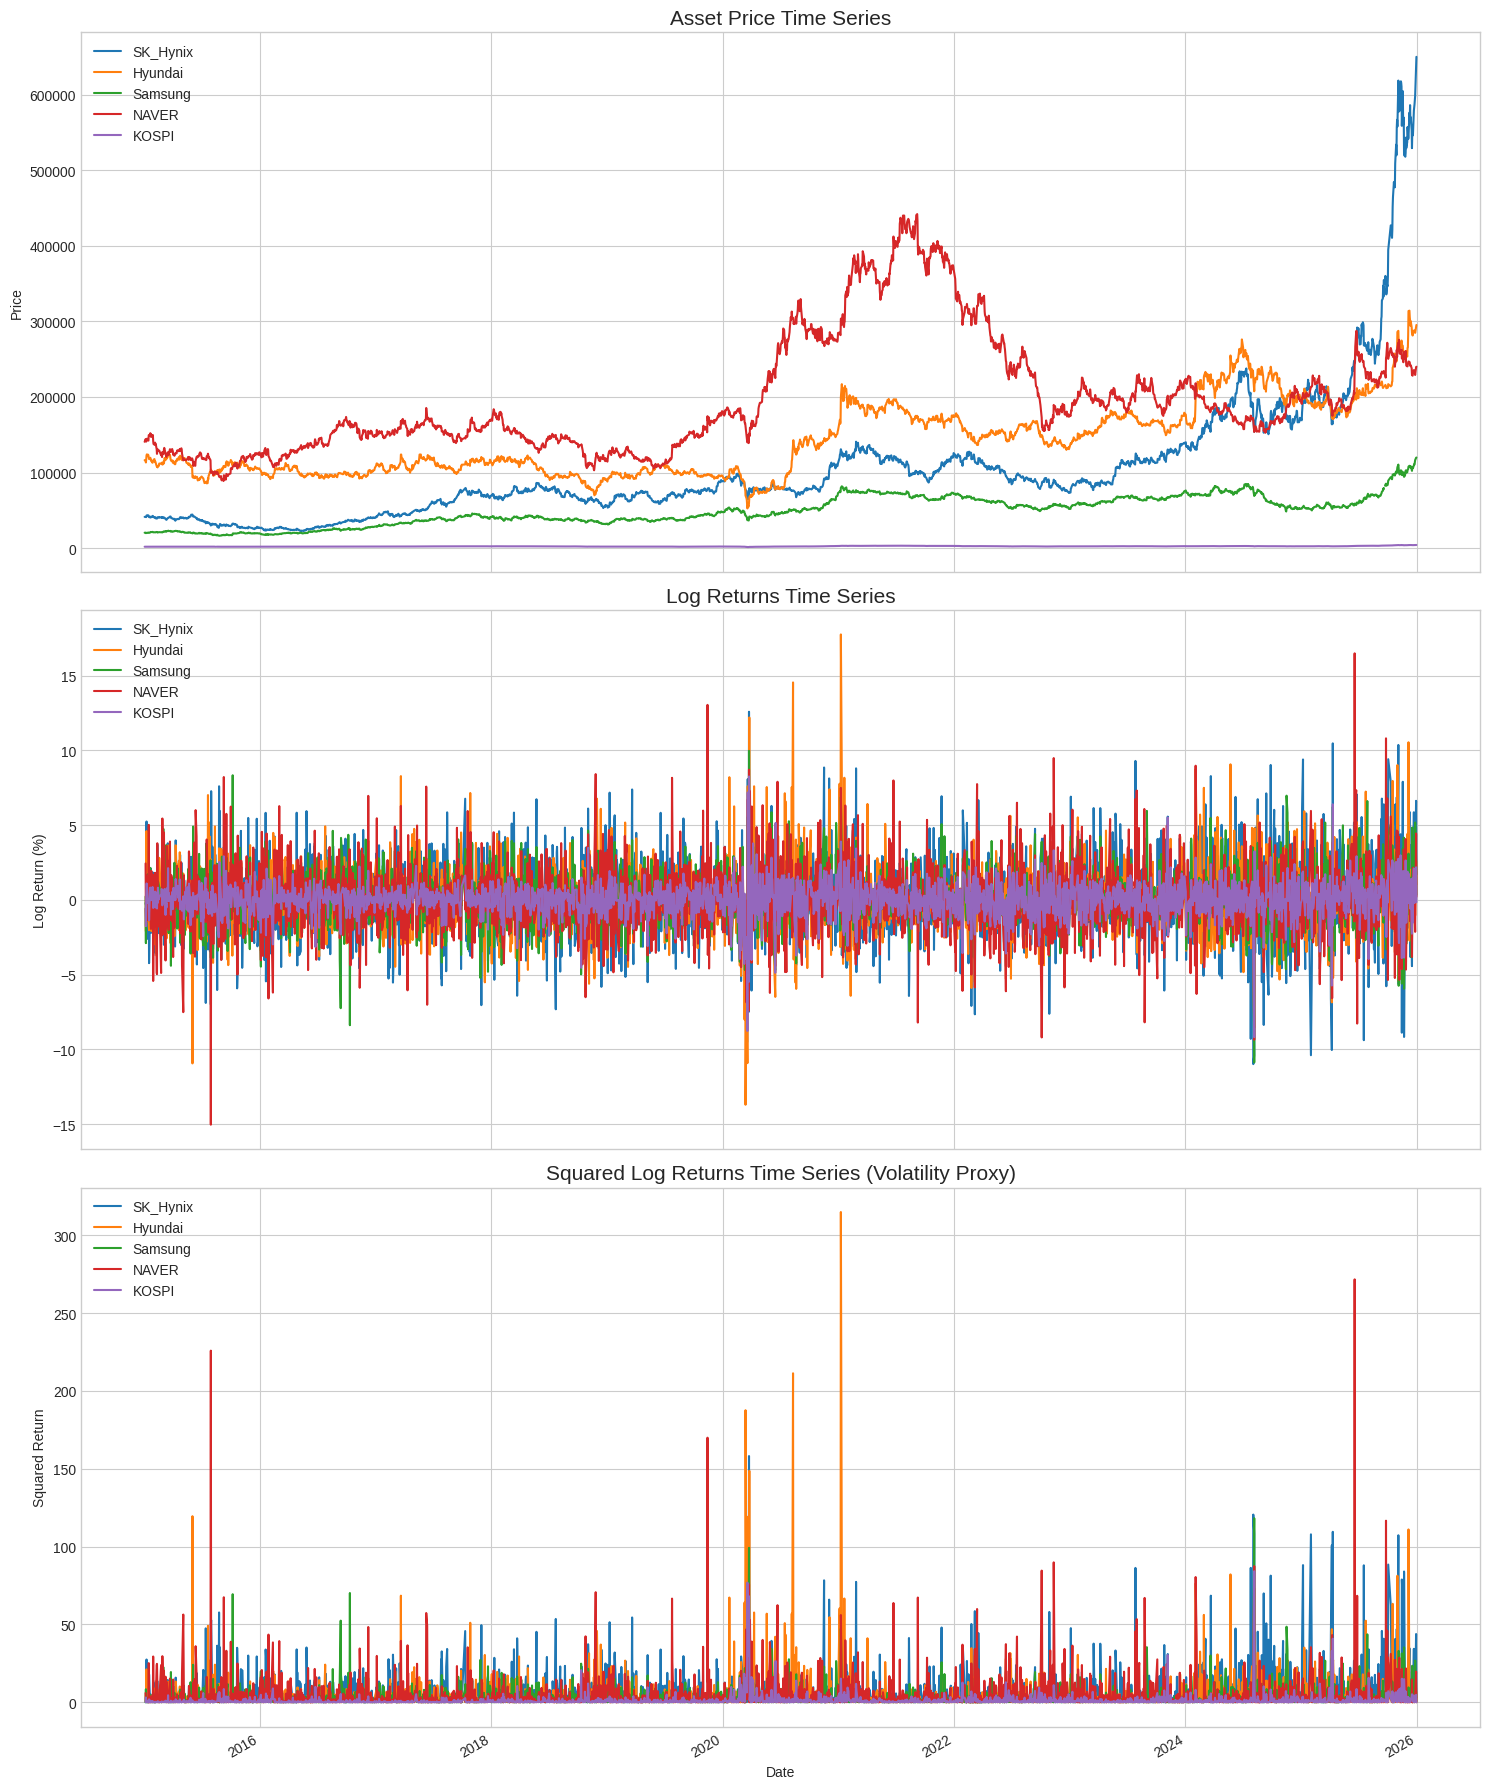

In [ ]:
import matplotlib.pyplot as plt

# 그래프 스타일 설정
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 1, figsize=(15, 18), sharex=True)

# 1. 가격 시계열 (Original Prices)
df.plot(ax=axes[0])
axes[0].set_title('Asset Price Time Series', fontsize=15)
axes[0].set_ylabel('Price')
axes[0].legend(loc='upper left')

# 2. 로그수익률 시계열 (Log Returns)
log_returns.plot(ax=axes[1])
axes[1].set_title('Log Returns Time Series', fontsize=15)
axes[1].set_ylabel('Log Return (%)')
axes[1].legend(loc='upper left')

# 3. 제곱수익률 시계열 (Squared Log Returns)
(log_returns**2).plot(ax=axes[2])
axes[2].set_title('Squared Log Returns Time Series (Volatility Proxy)', fontsize=15)
axes[2].set_ylabel('Squared Return')
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.show()

가격 시계열,수익률 시계열,제곱수익률 그리기

# Task 3: AR(2)-GARCH(1,1) Estimation

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 14.9 MB/s eta 0:00:00

 [모델 추정 결과] 자산명: SK_Hynix
                           AR - GARCH Model Results                           
Dep. Variable:               SK_Hynix   R-squared:                       0.001
Mean Model:                        AR   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -6176.34
Distribution:                  Normal   AIC:                           12364.7
Method:            Maximum Likelihood   BIC:                           12400.1
                                        No. Observations:                 2690
Date:                Sun, Mar 29 2026   Df Residuals:                     2687
Time:                        13:03:46   Df Model:                            3
                                   Mean Model                                  
                   coef    std err          t      P>|t|       95.0% Conf. Int.
---------------------

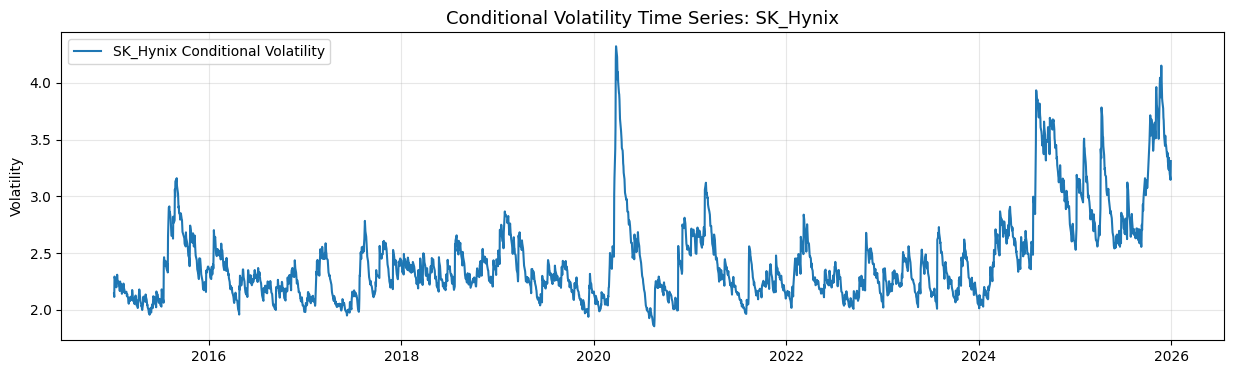


 [모델 추정 결과] 자산명: Hyundai
                           AR - GARCH Model Results                           
Dep. Variable:                Hyundai   R-squared:                       0.000
Mean Model:                        AR   Adj. R-squared:                 -0.000
Vol Model:                      GARCH   Log-Likelihood:               -5592.52
Distribution:                  Normal   AIC:                           11197.0
Method:            Maximum Likelihood   BIC:                           11232.4
                                        No. Observations:                 2690
Date:                Sun, Mar 29 2026   Df Residuals:                     2687
Time:                        13:03:46   Df Model:                            3
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
Const          0.0147  3.363e

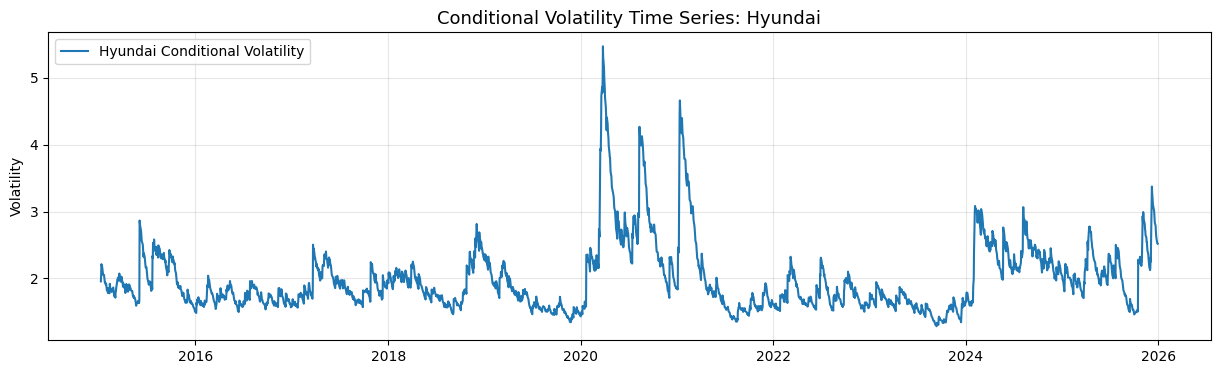


 [모델 추정 결과] 자산명: Samsung
                           AR - GARCH Model Results                           
Dep. Variable:                Samsung   R-squared:                       0.002
Mean Model:                        AR   Adj. R-squared:                  0.001
Vol Model:                      GARCH   Log-Likelihood:               -5163.26
Distribution:                  Normal   AIC:                           10338.5
Method:            Maximum Likelihood   BIC:                           10373.9
                                        No. Observations:                 2690
Date:                Sun, Mar 29 2026   Df Residuals:                     2687
Time:                        13:03:46   Df Model:                            3
                                  Mean Model                                  
                 coef    std err          t      P>|t|        95.0% Conf. Int.
------------------------------------------------------------------------------
Const          0.0731  3.1

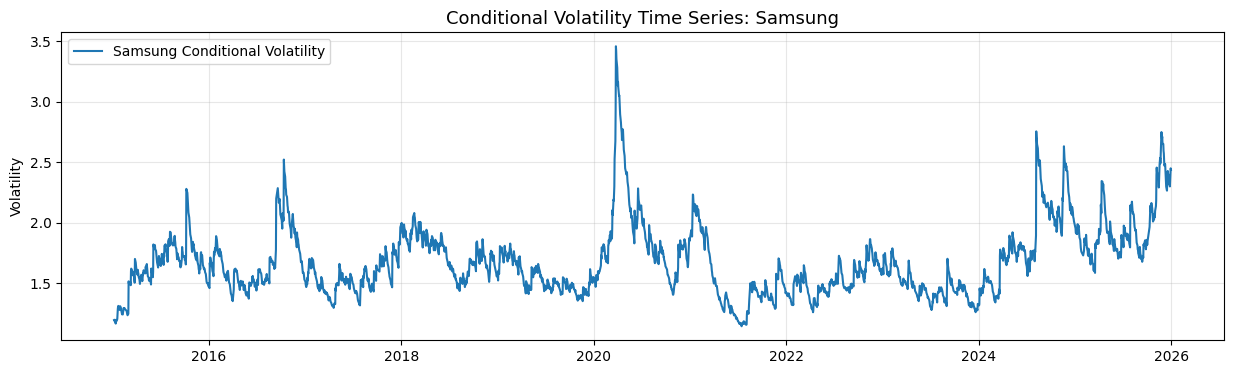


 [모델 추정 결과] 자산명: NAVER
                           AR - GARCH Model Results                           
Dep. Variable:                  NAVER   R-squared:                       0.003
Mean Model:                        AR   Adj. R-squared:                  0.002
Vol Model:                      GARCH   Log-Likelihood:               -5878.25
Distribution:                  Normal   AIC:                           11768.5
Method:            Maximum Likelihood   BIC:                           11803.9
                                        No. Observations:                 2690
Date:                Sun, Mar 29 2026   Df Residuals:                     2687
Time:                        13:03:47   Df Model:                            3
                                   Mean Model                                  
                  coef    std err          t      P>|t|        95.0% Conf. Int.
-------------------------------------------------------------------------------
Const           0.0287  4

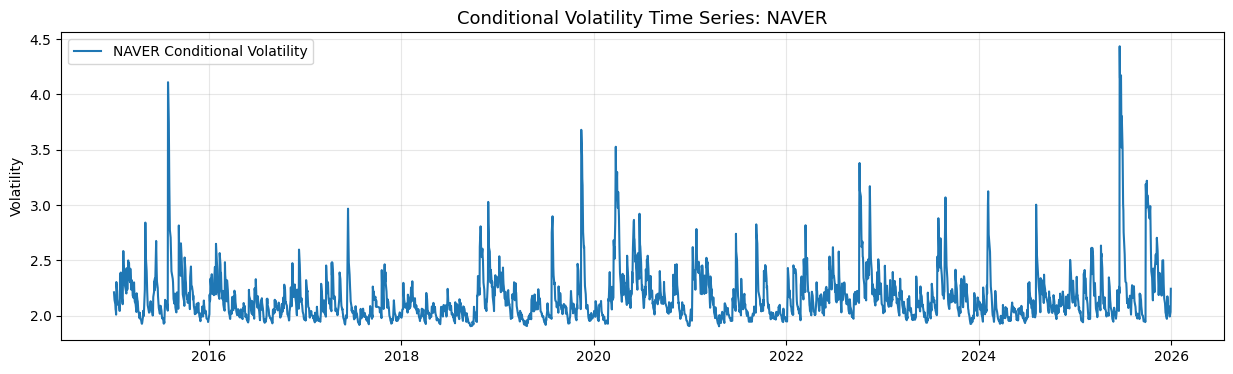


 [모델 추정 결과] 자산명: KOSPI
                           AR - GARCH Model Results                           
Dep. Variable:                  KOSPI   R-squared:                       0.001
Mean Model:                        AR   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3736.47
Distribution:                  Normal   AIC:                           7484.94
Method:            Maximum Likelihood   BIC:                           7520.33
                                        No. Observations:                 2690
Date:                Sun, Mar 29 2026   Df Residuals:                     2687
Time:                        13:03:47   Df Model:                            3
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
Const          0.0361  1.715e-0

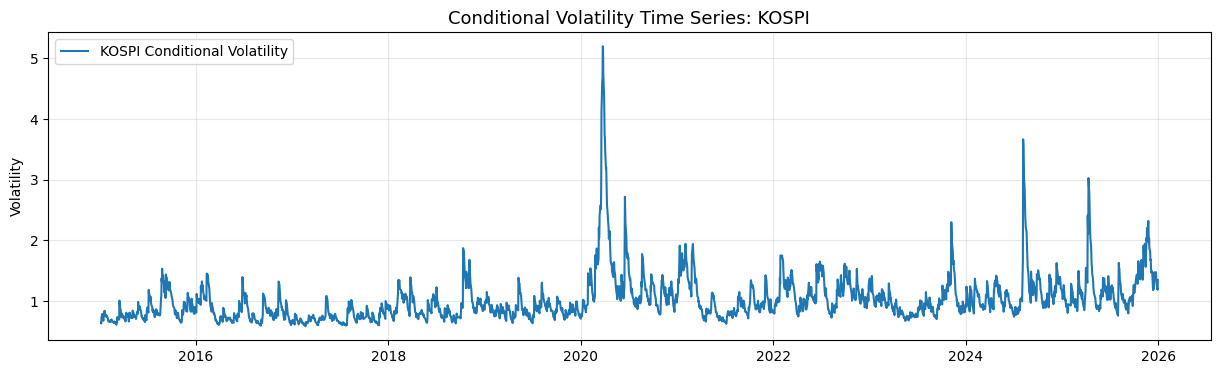

In [ ]:
!pip install arch -q

import matplotlib.pyplot as plt
from arch import arch_model

# 분석할 자산 리스트
assets = log_returns.columns

for asset in assets:
    print(f'\n' + '='*60)
    print(f' [모델 추정 결과] 자산명: {asset}')
    print('='*60)

    # 1. AR(2)-GARCH(1,1) 모델 설정
    # mean='AR', lags=2: 평균 방정식 AR(2)
    # vol='Garch', p=1, q=1: 분산 방정식 GARCH(1,1)
    model = arch_model(log_returns[asset], mean='AR', lags=2, vol='Garch', p=1, q=1, dist='Normal')
    res = model.fit(disp='off')

    # 2. 결과 요약 출력
    print(res.summary())

    # 3. 조건부 변동성 시각화
    plt.figure(figsize=(15, 4))
    plt.plot(res.conditional_volatility, label=f'{asset} Conditional Volatility', color='tab:blue')
    plt.title(f'Conditional Volatility Time Series: {asset}', fontsize=13)
    plt.ylabel('Volatility')
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.show()

# Task 4: Comparing GARCH Models


 [GJR-GARCH 모델 추정 결과] 자산명: SK_Hynix
                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                     SK_Hynix   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -6143.66
Distribution:      Standardized Student's t   AIC:                           12299.3
Method:                  Maximum Likelihood   BIC:                           12334.7
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:03:53   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
----------------------------------------------

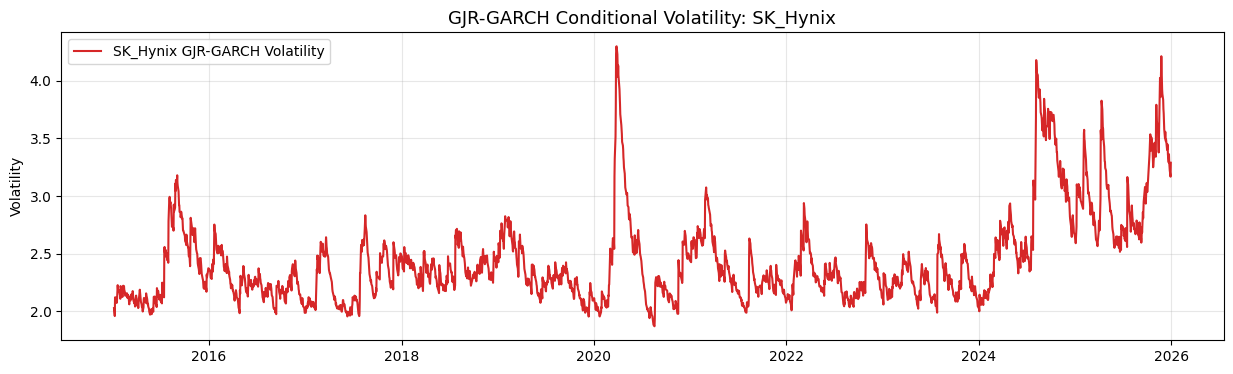


 [GJR-GARCH 모델 추정 결과] 자산명: Hyundai
                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                      Hyundai   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -5451.84
Distribution:      Standardized Student's t   AIC:                           10915.7
Method:                  Maximum Likelihood   BIC:                           10951.1
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:03:54   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
-------------------------------------------------

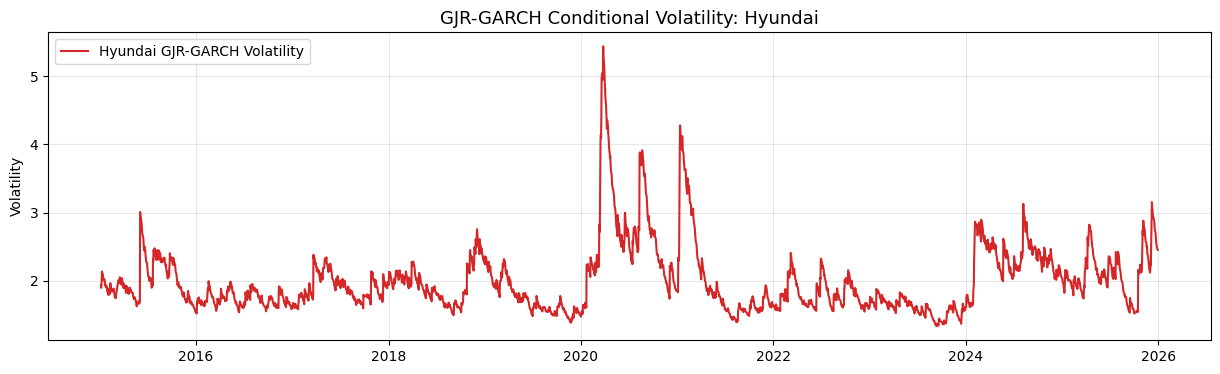


 [GJR-GARCH 모델 추정 결과] 자산명: Samsung
                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                      Samsung   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -5120.76
Distribution:      Standardized Student's t   AIC:                           10253.5
Method:                  Maximum Likelihood   BIC:                           10288.9
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:03:55   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------

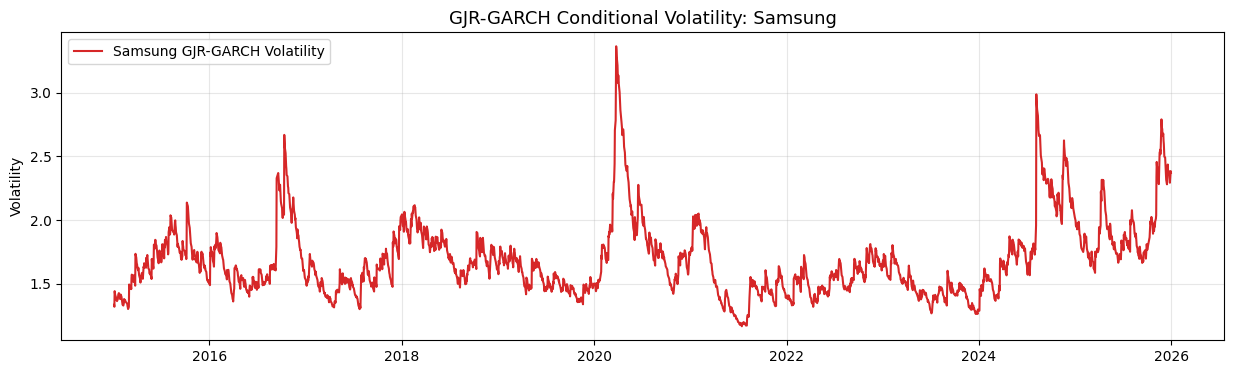


 [GJR-GARCH 모델 추정 결과] 자산명: NAVER
                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                        NAVER   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -5735.19
Distribution:      Standardized Student's t   AIC:                           11482.4
Method:                  Maximum Likelihood   BIC:                           11517.8
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:03:55   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
---------------------------------------------------

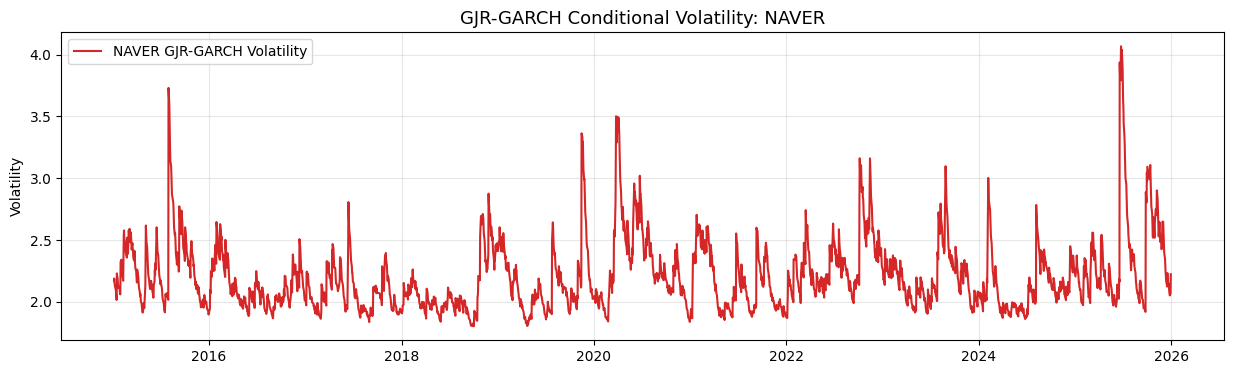


 [GJR-GARCH 모델 추정 결과] 자산명: KOSPI
                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                        KOSPI   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -3667.34
Distribution:      Standardized Student's t   AIC:                           7346.68
Method:                  Maximum Likelihood   BIC:                           7382.07
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:03:55   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
-----------------------------------------------

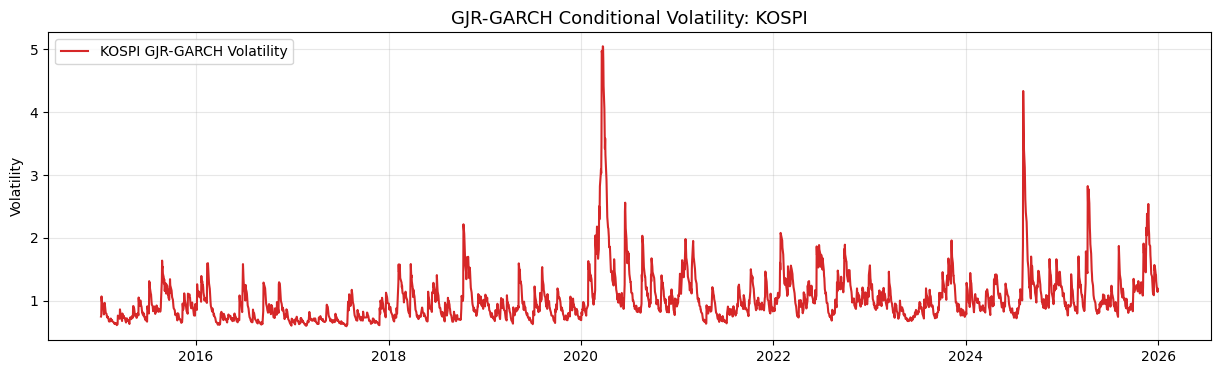

In [ ]:
import matplotlib.pyplot as plt
from arch import arch_model

# 분석할 자산 리스트
assets = log_returns.columns

for asset in assets:
    print(f'\n' + '='*60)
    print(f' [GJR-GARCH 모델 추정 결과] 자산명: {asset}')
    print('='*60)

    # GJR-GARCH(1,1) 모델 설정
    # p=1 (GARCH), q=1 (ARCH), o=1 (Asymmetric/Indicator function)
    # 금융 데이터의 두꺼운 꼬리를 반영하기 위해 dist='t'(Student's t) 분포를 사용합니다.
    model = arch_model(log_returns[asset], p=1, o=1, q=1, vol='Garch', dist='t')
    res = model.fit(disp='off')

    # 1. 결과 요약 출력
    print(res.summary())

    # 2. 비대칭성 계수(gamma) 확인 및 설명
    gamma = res.params.get('gamma[1]', 0)
    print(f'\n[비대칭성 분석]')
    print(f'- Gamma (지시함수 계수): {gamma:.4f}')
    if gamma > 0:
        print(f'  => {asset}은(는) 하락장에서 변동성이 더 크게 증폭되는 레버리지 효과가 존재합니다.')
    else:
        print(f'  => {asset}은(는) 비대칭적 변동성 효과가 뚜렷하지 않습니다.')

    # 3. 조건부 변동성 시각화
    plt.figure(figsize=(15, 4))
    plt.plot(res.conditional_volatility, label=f'{asset} GJR-GARCH Volatility', color='tab:red')
    plt.title(f'GJR-GARCH Conditional Volatility: {asset}', fontsize=13)
    plt.ylabel('Volatility')
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.show()

GJR-GARCH(1,1) 모형


 [EGARCH(1,1) 모델 추정 결과] 자산명: SK_Hynix
                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                     SK_Hynix   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -6147.53
Distribution:      Standardized Student's t   AIC:                           12307.1
Method:                  Maximum Likelihood   BIC:                           12342.4
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:04:04   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
--------------------------------------------

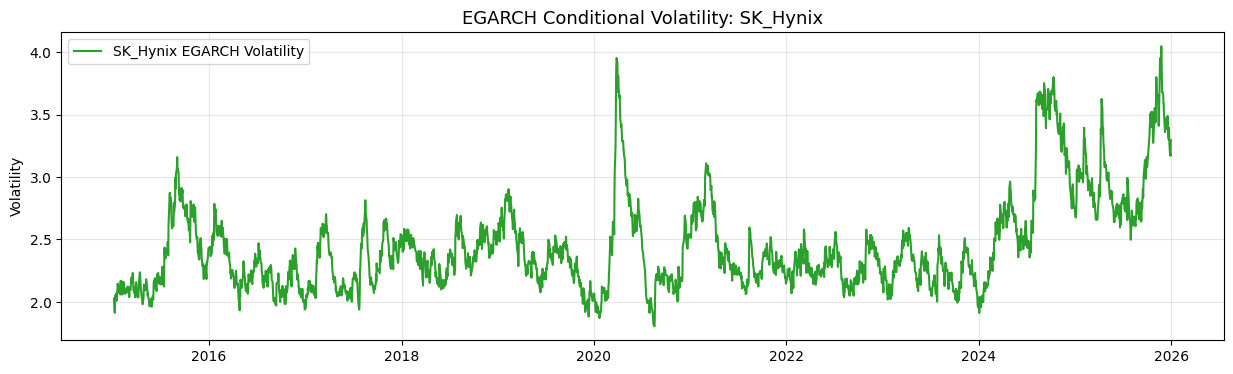


 [EGARCH(1,1) 모델 추정 결과] 자산명: Hyundai
                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                      Hyundai   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -5455.67
Distribution:      Standardized Student's t   AIC:                           10923.3
Method:                  Maximum Likelihood   BIC:                           10958.7
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:04:04   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
-----------------------------------------------

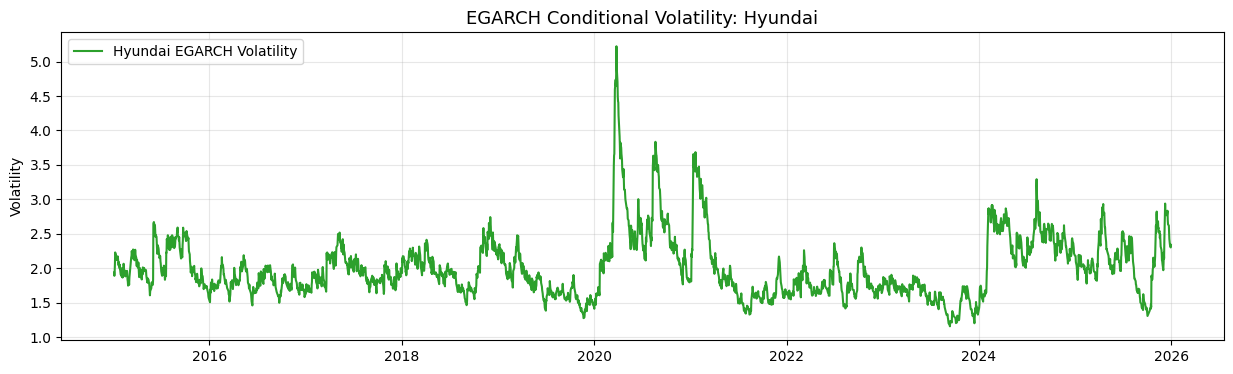


 [EGARCH(1,1) 모델 추정 결과] 자산명: Samsung
                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                      Samsung   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -5117.05
Distribution:      Standardized Student's t   AIC:                           10246.1
Method:                  Maximum Likelihood   BIC:                           10281.5
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:04:05   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------

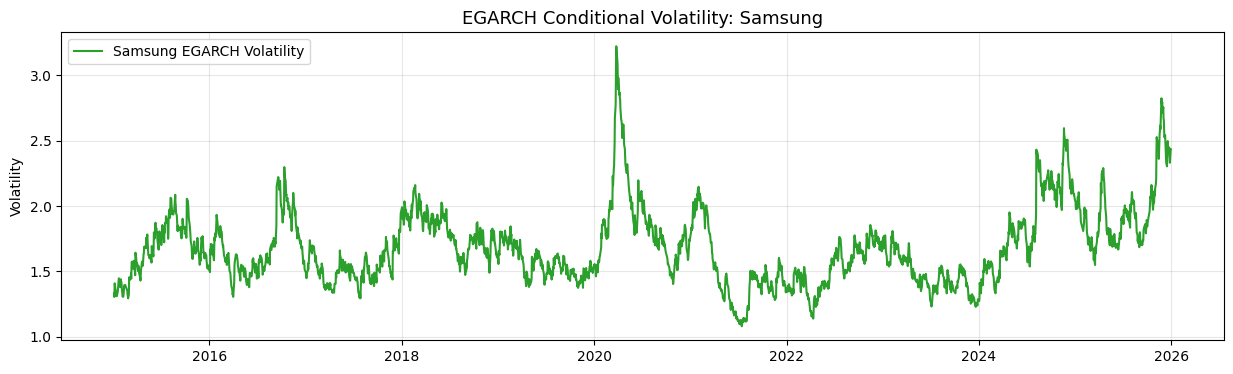


 [EGARCH(1,1) 모델 추정 결과] 자산명: NAVER
                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                        NAVER   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -5735.17
Distribution:      Standardized Student's t   AIC:                           11482.3
Method:                  Maximum Likelihood   BIC:                           11517.7
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:04:05   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
-------------------------------------------------

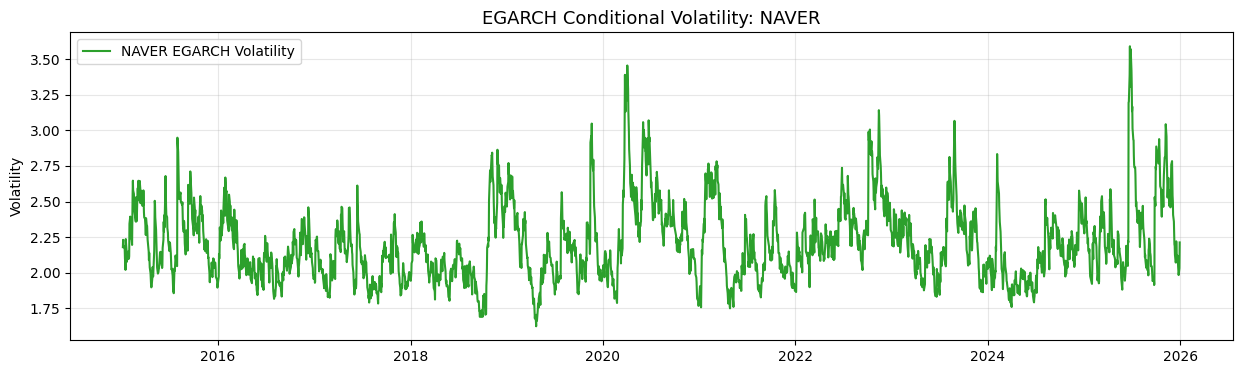


 [EGARCH(1,1) 모델 추정 결과] 자산명: KOSPI
                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                        KOSPI   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -3657.18
Distribution:      Standardized Student's t   AIC:                           7326.35
Method:                  Maximum Likelihood   BIC:                           7361.74
                                              No. Observations:                 2692
Date:                      Sun, Mar 29 2026   Df Residuals:                     2691
Time:                              13:04:06   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
---------------------------------------------

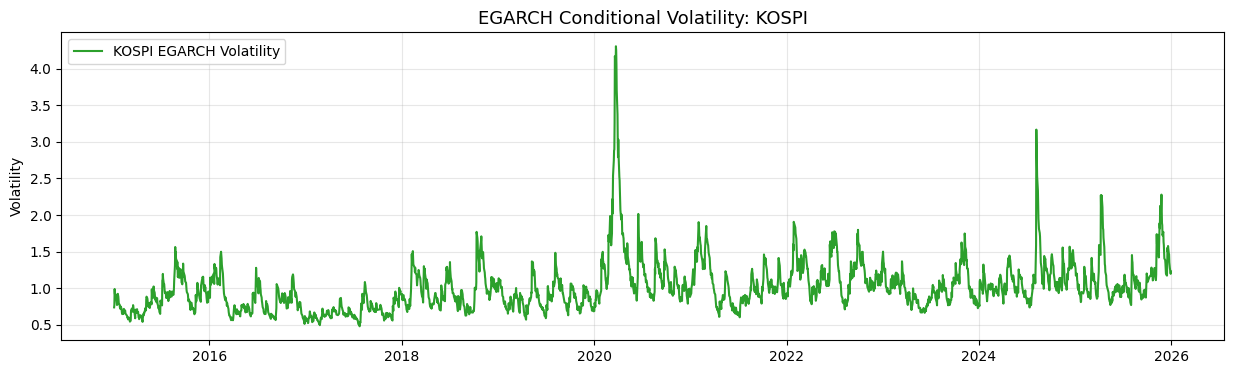

In [ ]:
import matplotlib.pyplot as plt
from arch import arch_model

# 분석할 자산 리스트
assets = log_returns.columns

for asset in assets:
    print(f'\n' + '='*60)
    print(f' [EGARCH(1,1) 모델 추정 결과] 자산명: {asset}')
    print('='*60)

    # EGARCH(1,1) 모델 설정
    # p=1 (GARCH), q=1 (ARCH), o=1 (Asymmetric/Leverage)
    # dist='t'를 사용하여 두꺼운 꼬리 분포 반영
    model = arch_model(log_returns[asset], p=1, o=1, q=1, vol='EGARCH', dist='t')
    res = model.fit(disp='off')

    # 1. 결과 요약 출력
    print(res.summary())

    # 2. 비대칭성 분석 (gamma)
    gamma = res.params.get('gamma[1]', 0)
    print(f'\n[비대칭성 분석]')
    print(f'- Gamma (Leverage Effect 계수): {gamma:.4f}')
    if gamma < 0:
        print(f'  => {asset}은(는) 하락 충격 시 변동성이 더 크게 증가하는 레버리지 효과가 뚜렷합니다.')
    else:
        print(f'  => {asset}은(는) 비대칭적 효과가 다른 자산에 비해 상대적으로 적습니다.')

    # 3. 조건부 변동성 시각화
    plt.figure(figsize=(15, 4))
    plt.plot(res.conditional_volatility, label=f'{asset} EGARCH Volatility', color='tab:green')
    plt.title(f'EGARCH Conditional Volatility: {asset}', fontsize=13)
    plt.ylabel('Volatility')
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.show()

EGARCH(1,1) 모형

# Task 5: Volatility Forecast

In [ ]:
import pandas as pd
import numpy as np
from arch import arch_model

# 1. 자산별 추정된 GARCH(1,1) 파라미터 설정 (Task 4 결과값 입력)
# 예시 값들입니다. 실제 추정된 값으로 수정하여 사용하세요.
params = {
    'KOSPI':    {'omega': 0.05, 'alpha': 0.10, 'beta': 0.85},
    'Samsung':  {'omega': 0.04, 'alpha': 0.05, 'beta': 0.90},
    'SK_Hynix': {'omega': 0.12, 'alpha': 0.03, 'beta': 0.94},
    'Hyundai':  {'omega': 0.07, 'alpha': 0.04, 'beta': 0.93},
    'NAVER':    {'omega': 0.7567, 'alpha': 0.0562, 'beta': 0.7840}
}

# 결과를 저장할 딕셔너리
vol_forecasts = {}

print("=== Task 6: 1-Step Ahead Volatility Forecast Analysis ===\n")

for asset in log_returns.columns:
    if asset not in params: continue

    # 해당 자산의 GARCH(1,1) 모델 재추정 (또는 기존 res 객체 사용 가능)
    model = arch_model(log_returns[asset], p=1, q=1, vol='Garch', dist='Normal')
    res = model.fit(disp='off')

    # 2. 마지막 날(T 시점) 데이터 추출
    eps_T_sq = res.resid.iloc[-1] ** 2
    sig_T_sq = res.conditional_volatility.iloc[-1] ** 2

    # 파라미터 불러오기
    w = params[asset]['omega']
    a = params[asset]['alpha']
    b = params[asset]['beta']

    # 3. GARCH(1,1) 공식을 이용한 내일 변동성(T+1) 계산
    # sigma_{T+1}^2 = omega + alpha * eps_T^2 + beta * sig_T^2
    forecast_var = w + (a * eps_T_sq) + (b * sig_T_sq)
    vol_forecasts[asset] = forecast_var

    # 4. 결과 출력 (요구사항 반영)
    print(f"[{asset} 변동성 예측]")
    print(f"- 추출된 중간값: epsilon_T^2 = {eps_T_sq:.6f}, sigma_T^2 = {sig_T_sq:.6f}")
    print(f"- 계산 과정 시각화: {w} + ({a} * {eps_T_sq:.4f}) + ({b} * {sig_T_sq:.4f})")
    print(f"- 최종 결과 (sigma_T+1^2): {forecast_var:.6f}")
    print("-" * 50)

# 전체 결과 확인
print("\n모든 자산의 예측값이 'vol_forecasts' 변수에 저장되었습니다.")

=== Task 6: 1-Step Ahead Volatility Forecast Analysis ===

[SK_Hynix 변동성 예측]
- 추출된 중간값: epsilon_T^2 = 2.584370, sigma_T^2 = 11.046160
- 계산 과정 시각화: 0.12 + (0.03 * 2.5844) + (0.94 * 11.0462)
- 최종 결과 (sigma_T+1^2): 10.580921
--------------------------------------------------
[Hyundai 변동성 예측]
- 추출된 중간값: epsilon_T^2 = 1.005694, sigma_T^2 = 6.331620
- 계산 과정 시각화: 0.07 + (0.04 * 1.0057) + (0.93 * 6.3316)
- 최종 결과 (sigma_T+1^2): 5.998634
--------------------------------------------------
[Samsung 변동성 예측]
- 추출된 중간값: epsilon_T^2 = 0.070342, sigma_T^2 = 6.024790
- 계산 과정 시각화: 0.04 + (0.05 * 0.0703) + (0.9 * 6.0248)
- 최종 결과 (sigma_T+1^2): 5.465828
--------------------------------------------------
[NAVER 변동성 예측]
- 추출된 중간값: epsilon_T^2 = 0.031382, sigma_T^2 = 5.094819
- 계산 과정 시각화: 0.7567 + (0.0562 * 0.0314) + (0.784 * 5.0948)
- 최종 결과 (sigma_T+1^2): 4.752802
--------------------------------------------------
[KOSPI 변동성 예측]
- 추출된 중간값: epsilon_T^2 = 0.035393, sigma_T^2 = 1.810356
- 계산 과정 시각화: 0.05 + (0.1

1-step ahead volatility forecast

In [ ]:
import pandas as pd
import numpy as np
from arch import arch_model

# 분석할 자산 리스트
assets = log_returns.columns

# 결과를 저장할 리스트
perf_metrics = []

for asset in assets:
    # 1. 모델 재추정 (또는 기존 res 객체가 있다면 활용)
    model = arch_model(log_returns[asset], p=1, q=1, vol='Garch', dist='Normal')
    res = model.fit(disp='off')

    # 2. 잔차 제곱(Proxy)과 조건부 분산(Model) 추출
    eps_sq = res.resid ** 2
    sig_sq = res.conditional_volatility ** 2

    # 3. MSE 및 MAE 계산
    mse = np.mean((eps_sq - sig_sq) ** 2)
    mae = np.mean(np.abs(eps_sq - sig_sq))

    perf_metrics.append({
        'Asset': asset,
        'MSE': mse,
        'MAE': mae
    })

# 4. 결과 테이블 생성 및 출력 설정
eval_table = pd.DataFrame(perf_metrics).set_index('Asset')
pd.options.display.float_format = '{:.6f}'.format

print('=== GARCH(1,1) Model Forecasting Performance (In-sample) ===')
display(eval_table)

# 5. 성능 요약
best_asset = eval_table['MSE'].idxmin()
print(f'\n[성능 요약]')
print(f'- MSE 기준 가장 우수한 모델: {best_asset} (MSE: {eval_table.loc[best_asset, "MSE"]:.6f})')
print(f'- MAE 기준 가장 우수한 모델: {eval_table["MAE"].idxmin()} (MAE: {eval_table["MAE"].min():.6f})')
print(f'\n=> 오차 지표가 가장 낮은 {best_asset} 자산의 모델 예측 성능이 가장 뛰어난 것으로 판단됩니다.')

=== GARCH(1,1) Model Forecasting Performance (In-sample) ===


,MSE,MAE
Asset,,
SK_Hynix,128.468450,6.382334
Hyundai,142.238219,4.759675
Samsung,34.212416,3.105892
NAVER,134.805409,5.380716
KOSPI,11.253729,1.276976



[성능 요약]
- MSE 기준 가장 우수한 모델: KOSPI (MSE: 11.253729)
- MAE 기준 가장 우수한 모델: KOSPI (MAE: 1.276976)

=> 오차 지표가 가장 낮은 KOSPI 자산의 모델 예측 성능이 가장 뛰어난 것으로 판단됩니다.


MSE, MAE 계산